# 2º Trabalho de Fundamentos de IA — Etapa 2: Aprendizado Linear
**Domínio:** Educação (SAEB 2021/2023 + Censo 2010) · **IComp/UFAM** · Prof. Edjard Mota

Esta etapa cobre as 6 tarefas do enunciado:

1. Variável-alvo **contínua**: $\Delta$ = `MEDIA_12_MT_2023` − `MEDIA_12_MT_2021` (variação, em pontos, da média de Matemática do Ensino Médio)
2. Regressão linear **univariada** (fórmula fechada)
3. Regressão **multivariada** com **gradiente descendente do zero**
4. **Regularização L2 (Ridge)** e curva de coeficientes × λ
5. **Regressão logística** (sigmoide + gradiente) para o problema da Etapa 1 (`ALVO_MELHORA`)
6. Comparação com `LinearRegression`, `Ridge` e `LogisticRegression` do scikit-learn — **única parte que usa o scikit-learn** (seção 5)

O conjunto de dados é o mesmo da Etapa 1 (município × dependência × localização, categorias exclusivas; 3.519 exemplos), embutido no notebook. A validação é a mesma: **5-fold agrupado por município**, para que o mesmo município nunca caia em treino e teste ao mesmo tempo. As partições, as métricas ($R^2$, RMSE, acurácia) e todos os modelos são implementados aqui com `numpy`/`pandas`; o scikit-learn só entra na seção 5, para a comparação exigida pelo enunciado.

## 0. Configuração e dados

In [ ]:
import io, gzip, base64, warnings
warnings.filterwarnings('ignore')
import numpy as np, pandas as pd, matplotlib.pyplot as plt

SEED = 42
np.random.seed(SEED)
pd.set_option('display.width', 160, 'display.max_columns', 30)

# Conjunto da Etapa 1 (SAEB 2021 + SAEB 2023 + IDHM_R do Censo 2010), já filtrado e cruzado
EMBUTIDO = "..."
df = pd.read_csv(io.StringIO(gzip.decompress(base64.b64decode(EMBUTIDO)).decode()))
print(df.shape); df.head()

(3519, 7)


,CO_UF,CO_MUNICIPIO,DEPENDENCIA_ADM,LOCALIZACAO,MEDIA_12_MT_2021,MEDIA_12_MT_2023,IDHM_R
0,11,1100015,Estadual,Urbana,259.69,274.69,0.657
1,11,1100023,Estadual,Urbana,266.76,269.63,0.716
2,11,1100049,Estadual,Urbana,267.95,262.62,0.727
3,11,1100064,Estadual,Urbana,265.44,265.89,0.676
4,11,1100072,Estadual,Rural,280.76,268.30,0.630


### 0.1 Alvo contínuo e atributos numéricos
- **Alvo contínuo:** `DELTA` = média 2023 − média 2021 (pontos de SAEB).
- **Alvo de classificação (Etapa 1):** `ALVO_MELHORA` = 1 se `DELTA` > 0. Note que ele é só o **sinal** de `DELTA`.
- **Atributos** (numéricos, pois a regressão exige): `MEDIA_12_MT_2021`, `IDHM_R`, `Rural` (0/1), `Estadual` (0/1; Federal e Municipal são raras e ficam na categoria-base) e a região (a partir do código da UF; **Norte** é a categoria-base). Usamos região em vez das 27 UFs para manter poucos coeficientes interpretáveis.

count    3519.00
mean        3.78
std        12.90
min       -62.91
25%        -3.76
50%         3.48
75%        10.79
max       142.90

Proporção de DELTA > 0: 0.631


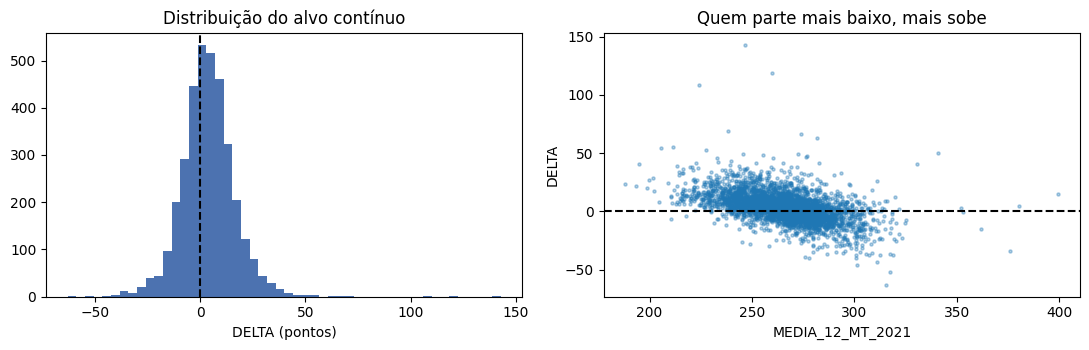

In [ ]:
df['DELTA'] = df.MEDIA_12_MT_2023 - df.MEDIA_12_MT_2021
df['ALVO_MELHORA'] = (df.DELTA > 0).astype(int)
reg = {1: 'Norte', 2: 'NE', 3: 'SE', 4: 'S', 5: 'CO'}
df['REGIAO'] = (df.CO_UF // 10).map(reg)
df['Rural'] = (df.LOCALIZACAO == 'Rural').astype(int)
df['Estadual'] = (df.DEPENDENCIA_ADM == 'Estadual').astype(int)
for r in ['NE', 'SE', 'S', 'CO']: df['Reg_' + r] = (df.REGIAO == r).astype(int)

FEATS = ['MEDIA_12_MT_2021', 'IDHM_R', 'Rural', 'Estadual', 'Reg_NE', 'Reg_SE', 'Reg_S', 'Reg_CO']
X_all, y_all = df[FEATS].values.astype(float), df.DELTA.values
yc_all = df.ALVO_MELHORA.values; groups = df.CO_MUNICIPIO.values

print(df.DELTA.describe().round(2).to_string())
print(f"\nProporção de DELTA > 0: {yc_all.mean():.3f}")
fig, axs = plt.subplots(1, 2, figsize=(11, 3.6))
axs[0].hist(df.DELTA, bins=50, color='#4c72b0'); axs[0].axvline(0, c='k', ls='--'); axs[0].set_xlabel('DELTA (pontos)'); axs[0].set_title('Distribuição do alvo contínuo')
axs[1].scatter(df.MEDIA_12_MT_2021, df.DELTA, s=5, alpha=.35); axs[1].axhline(0, c='k', ls='--')
axs[1].set_xlabel('MEDIA_12_MT_2021'); axs[1].set_ylabel('DELTA'); axs[1].set_title('Quem parte mais baixo, mais sobe')
plt.tight_layout(); plt.show()

### 0.2 Partições, métricas e padronização (implementadas aqui)
5 partições agrupadas por município e balanceadas pela classe `ALVO_MELHORA` (função própria, a mesma da Etapa 1). **A padronização dos atributos (média 0, desvio 1) é sempre ajustada só no treino de cada partição**, para não vazar informação do teste.

In [ ]:
def kfold_por_grupo(y, grupos, k=5, seed=SEED):
    # 5-fold agrupado por município (cada município inteiro em UMA partição), balanceando tamanho e proporção da classe 1
    # (mesma função da Etapa 1)
    rng = np.random.RandomState(seed); y = np.asarray(y); grupos = np.asarray(grupos)
    ids = pd.unique(grupos); rng.shuffle(ids)
    info = pd.DataFrame({'g': grupos, 'y': y}).groupby('g').y.agg(['size', 'sum']).loc[ids]
    info = info.sort_values('size', ascending=False, kind='stable')
    tam, pos, dest, p1 = np.zeros(k), np.zeros(k), {}, y.mean()
    for g, (n, s_) in info.iterrows():
        f = min(range(k), key=lambda j: (tam[j], pos[j] - p1 * tam[j]))
        dest[g] = f; tam[f] += n; pos[f] += s_
    fold = np.array([dest[g] for g in grupos])
    return [(np.where(fold != j)[0], np.where(fold == j)[0]) for j in range(k)]

# métricas
def r2_score(y, p): return 1 - ((y - p) ** 2).sum() / ((y - y.mean()) ** 2).sum()
def rmse(y, p): return float(np.sqrt(((y - p) ** 2).mean()))

folds = kfold_por_grupo(yc_all, groups)
print([(len(a), len(b)) for a, b in folds], '| municípios disjuntos entre treino e teste:',
      all(set(groups[a]).isdisjoint(groups[b]) for a, b in folds))

def padroniza(Xtr, Xte):
    mu, sd = Xtr.mean(0), Xtr.std(0); sd[sd == 0] = 1
    return (Xtr - mu) / sd, (Xte - mu) / sd, mu, sd

[(2815, 704), (2815, 704), (2815, 704), (2816, 703), (2815, 704)] | municípios disjuntos entre treino e teste: True


## 1. Regressão linear univariada (fórmula fechada)
Modelo $\hat y=\beta_0+\beta_1 x$, com $x$ = `MEDIA_12_MT_2021`. Mínimos quadrados:

$$\beta_1=\frac{\sum_i (x_i-\bar x)(y_i-\bar y)}{\sum_i (x_i-\bar x)^2},\qquad \beta_0=\bar y-\beta_1\bar x$$

Fórmula fechada : β0 = 90.1346, β1 = -0.3258
R² (treino todo) = 0.2586
5-fold: R² = 0.254 ± 0.021 | RMSE = 11.10 pontos


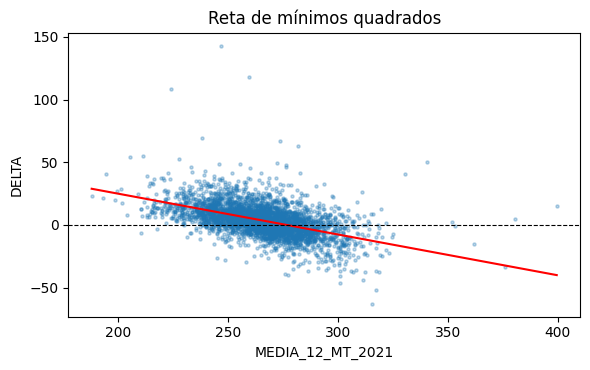

In [ ]:
def uni_fit(x, y):
    b1 = ((x - x.mean()) * (y - y.mean())).sum() / ((x - x.mean()) ** 2).sum()
    return y.mean() - b1 * x.mean(), b1

x = df.MEDIA_12_MT_2021.values
b0, b1 = uni_fit(x, y_all)
print(f'Fórmula fechada : β0 = {b0:.4f}, β1 = {b1:.4f}')
print(f'R² (treino todo) = {r2_score(y_all, b0 + b1 * x):.4f}')

# validação cruzada agrupada
r2s, rmses = [], []
for tr, te in folds:
    c0, c1 = uni_fit(x[tr], y_all[tr]); p = c0 + c1 * x[te]
    r2s.append(r2_score(y_all[te], p)); rmses.append(rmse(y_all[te], p))
R_UNI = dict(r2=np.mean(r2s), rmse=np.mean(rmses)); print(f'5-fold: R² = {R_UNI["r2"]:.3f} ± {np.std(r2s):.3f} | RMSE = {R_UNI["rmse"]:.2f} pontos')

plt.figure(figsize=(6, 3.8)); plt.scatter(x, y_all, s=5, alpha=.3)
xx = np.linspace(x.min(), x.max(), 50); plt.plot(xx, b0 + b1 * xx, c='r'); plt.axhline(0, c='k', ls='--', lw=.8)
plt.xlabel('MEDIA_12_MT_2021'); plt.ylabel('DELTA'); plt.title('Reta de mínimos quadrados'); plt.tight_layout(); plt.show()

**Atenção à interpretação:** $\Delta = M_{2023}-M_{2021}$ contém $M_{2021}$ com sinal negativo, e a nota de 2021 também traz ruído de medição. Por isso o coeficiente é **negativo por construção** (regressão à média): parte do $R^2$ é mecânica e **não** é evidência de efeito do Novo Ensino Médio.

## 2. Regressão multivariada com gradiente descendente (do zero)
Seguimos o pseudocódigo do enunciado (Listing 2): $w\leftarrow \mathbf 0$; a cada iteração, $\text{grad}=\sum_j (y_j-w\cdot x_j)\,x_j$ e $w\leftarrow w+\alpha\,\text{grad}/N$. Abaixo, (a) a versão **literal** com laço sobre exemplos e (b) a versão **vetorizada**, equivalente e muito mais rápida; verificamos que dão o mesmo resultado.

In [ ]:
def com_vies(X): return np.hstack([np.ones((len(X), 1)), X])

def gd_literal(X, y, alpha, num_iter):
    # transcrição direta do pseudocódigo (laço sobre j) — lenta, só para verificação
    Xb = com_vies(X); N, d1 = Xb.shape; w = np.zeros(d1)
    for _ in range(num_iter):
        grad = np.zeros(d1)
        for j in range(N):
            erro = y[j] - Xb[j] @ w
            grad = grad + erro * Xb[j]
        w = w + alpha * grad / N
    return w

def gd_linear(X, y, alpha=0.1, num_iter=2000, lam=0.0, hist=False):
    # Vetorizada. Objetivo: J = (1/2N)·Σ erro² + (λ/2N)·||w_(sem viés)||²  (o viés não é penalizado)
    Xb = com_vies(X); N, d1 = Xb.shape; w = np.zeros(d1); H = []
    pen = np.r_[0.0, np.ones(d1 - 1)]
    for _ in range(num_iter):
        erro = y - Xb @ w
        w = w + alpha * (Xb.T @ erro - lam * pen * w) / N
        if hist: H.append((erro ** 2).mean() / 2 + lam * (pen * w ** 2).sum() / (2 * N))
    return (w, H) if hist else w

# (a) verificação: literal × vetorizado (subconjunto pequeno, poucas iterações)
Xtr0, _, _, _ = padroniza(X_all[:300], X_all[:1]); y0 = y_all[:300]
w_lit, w_vec = gd_literal(Xtr0, y0, 0.1, 30), gd_linear(Xtr0, y0, 0.1, 30)
print('literal ≈ vetorizado:', np.allclose(w_lit, w_vec))

literal ≈ vetorizado: True


                  GD (próprio)  Eq. normais
intercepto              3.7823       3.7823
MEDIA_12_MT_2021       -6.8577      -6.8577
IDHM_R                 -1.5941      -1.5941
Rural                  -1.0990      -1.0990
Estadual               -0.6382      -0.6382
Reg_NE                  0.7056       0.7056
Reg_SE                  0.9320       0.9320
Reg_S                   2.4379       2.4379
Reg_CO                  2.2675       2.2675

máx |GD − eq. normais| = 0.0


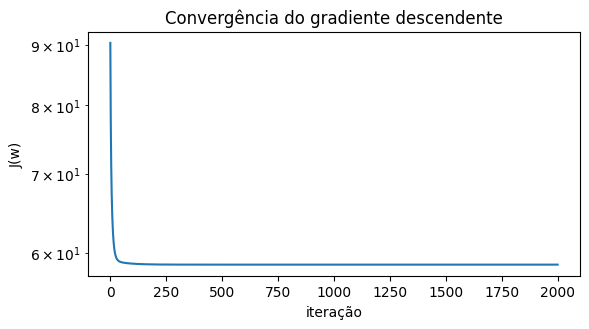

In [ ]:
# (b) ajuste no conjunto todo (padronizado) e comparação com a solução fechada (equações normais)
Xs, _, mu, sd = padroniza(X_all, X_all)
w_gd, hist = gd_linear(Xs, y_all, alpha=0.1, num_iter=2000, hist=True)
w_ne = np.linalg.solve(com_vies(Xs).T @ com_vies(Xs), com_vies(Xs).T @ y_all)       # equações normais
comp = pd.DataFrame({'GD (próprio)': w_gd, 'Eq. normais': w_ne}, index=['intercepto'] + FEATS)
print(comp.round(4)); print('\nmáx |GD − eq. normais| =', round(float(np.abs(w_gd - w_ne).max()), 6))
plt.figure(figsize=(6, 3.4)); plt.plot(hist); plt.yscale('log'); plt.xlabel('iteração'); plt.ylabel('J(w)'); plt.title('Convergência do gradiente descendente'); plt.tight_layout(); plt.show()

Os coeficientes são de atributos **padronizados**: cada um mede a variação de `DELTA` (em pontos) para +1 desvio-padrão do atributo, mantendo os demais fixos, o que permite comparar a importância entre atributos.

**Escolha do passo:** com atributos padronizados, $\alpha=0{,}1$ converge bem. O gráfico mostra a queda de $J$; com $\alpha$ muito grande o método diverge, e sem padronizar a convergência seria muito lenta.

In [ ]:
# Validação cruzada: regressão multivariada (GD próprio)
def cv_reg(fit_predict):
    r2s, rm = [], []
    for tr, te in folds:
        Xa, Xb_, _, _ = padroniza(X_all[tr], X_all[te]); p = fit_predict(Xa, y_all[tr], Xb_)
        r2s.append(r2_score(y_all[te], p)); rm.append(rmse(y_all[te], p))
    return np.mean(r2s), np.std(r2s), np.mean(rm)

gd_pred = lambda Xa, ya, Xb_: com_vies(Xb_) @ gd_linear(Xa, ya, 0.1, 2000)
R_GD = cv_reg(gd_pred)
print(f'Multivariada GD próprio : R² = {R_GD[0]:.3f} ± {R_GD[1]:.3f} | RMSE = {R_GD[2]:.2f}')
print(f'Univariada (fórmula)    : R² = {R_UNI["r2"]:.3f} | RMSE = {R_UNI["rmse"]:.2f}')

Multivariada GD próprio : R² = 0.287 ± 0.021 | RMSE = 10.86
Univariada (fórmula)    : R² = 0.254 | RMSE = 11.10


## 3. Regularização L2 (Ridge) e curva de coeficientes × λ
Penalizamos $\|w\|^2$ (sem o intercepto): $J=\frac1{2N}\sum(y-\hat y)^2+\frac{\lambda}{2N}\|w\|^2$. A solução fechada é $w=(X^\top X+\lambda I_0)^{-1}X^\top y$ ($I_0$ = identidade com 0 no intercepto), (comparada ao `Ridge(alpha=λ)` do scikit-learn na seção 5). O GD próprio recebe o termo $\lambda w$ no gradiente.

GD ridge ≈ solução fechada: True


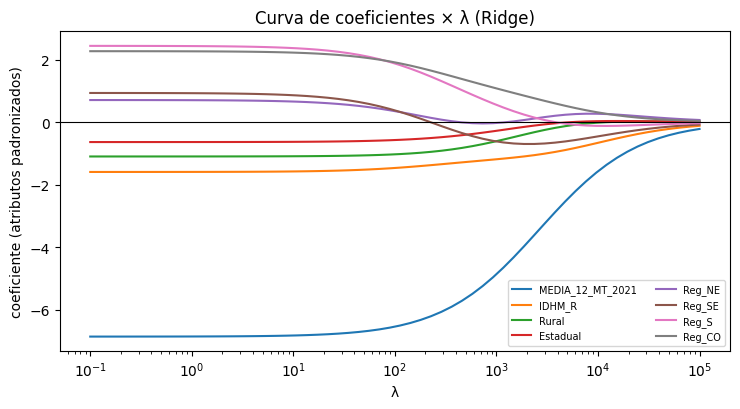

In [ ]:
def ridge_closed(X, y, lam):
    Xb = com_vies(X); I0 = np.eye(Xb.shape[1]); I0[0, 0] = 0
    return np.linalg.solve(Xb.T @ Xb + lam * I0, Xb.T @ y)

# verificação: GD com λ × solução fechada
lam_t = 500.0
w1, w2 = gd_linear(Xs, y_all, 0.1, 4000, lam=lam_t), ridge_closed(Xs, y_all, lam_t)
print('GD ridge ≈ solução fechada:', np.allclose(w1, w2, atol=1e-4))

lams = np.logspace(-1, 5, 60)
path = np.array([ridge_closed(Xs, y_all, l)[1:] for l in lams])
fig, ax = plt.subplots(figsize=(7.5, 4.2))
for k, nome in enumerate(FEATS): ax.plot(lams, path[:, k], label=nome)
ax.set_xscale('log'); ax.axhline(0, c='k', lw=.8); ax.set_xlabel('λ'); ax.set_ylabel('coeficiente (atributos padronizados)')
ax.set_title('Curva de coeficientes × λ (Ridge)'); ax.legend(fontsize=7, ncol=2); plt.tight_layout(); plt.show()

λ de maior R² no CV: 13.7  (R² = 0.2875 ± 0.0212)
λ mais regularizado dentro de 1 desvio-padrão: 731.8  (R² = 0.2714)


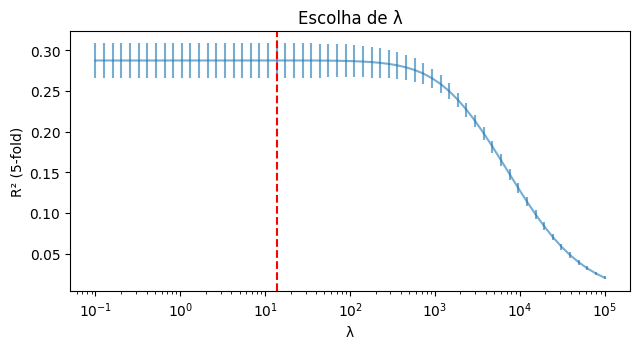

Ridge (GD próprio, λ=13.7) : R² = 0.287 ± 0.021 | RMSE = 10.86


In [ ]:
# Escolha de λ por validação cruzada agrupada (padronização ajustada em cada treino)
def cv_ridge(lam):
    r2s = []
    for tr, te in folds:
        Xa, Xb_, _, _ = padroniza(X_all[tr], X_all[te])
        r2s.append(r2_score(y_all[te], com_vies(Xb_) @ ridge_closed(Xa, y_all[tr], lam)))
    return np.mean(r2s), np.std(r2s)

cvs = np.array([cv_ridge(l) for l in lams])
i_best = cvs[:, 0].argmax(); i_1se = np.where(cvs[:, 0] >= cvs[i_best, 0] - cvs[i_best, 1])[0].max()
LAM = lams[i_best]
print(f'λ de maior R² no CV: {LAM:.1f}  (R² = {cvs[i_best,0]:.4f} ± {cvs[i_best,1]:.4f})')
print(f'λ mais regularizado dentro de 1 desvio-padrão: {lams[i_1se]:.1f}  (R² = {cvs[i_1se,0]:.4f})')
plt.figure(figsize=(6.5, 3.6)); plt.errorbar(lams, cvs[:, 0], cvs[:, 1], alpha=.6); plt.axvline(LAM, c='r', ls='--')
plt.xscale('log'); plt.xlabel('λ'); plt.ylabel('R² (5-fold)'); plt.title('Escolha de λ'); plt.tight_layout(); plt.show()

# Ridge com λ escolhido (GD próprio)
R_RIDGE = cv_reg(lambda Xa, ya, Xb_: com_vies(Xb_) @ gd_linear(Xa, ya, 0.1, 3000, lam=LAM))
print(f'Ridge (GD próprio, λ={LAM:.1f}) : R² = {R_RIDGE[0]:.3f} ± {R_RIDGE[1]:.3f} | RMSE = {R_RIDGE[2]:.2f}')

## 4. Regressão logística (sigmoide + gradiente) para `ALVO_MELHORA`
Mesmo problema da Etapa 1, agora com modelo linear: $P(y=1\mid x)=\sigma(w\cdot x)$, $\sigma(z)=1/(1+e^{-z})$. Perda (entropia cruzada) $J=-\frac1N\sum[y\log p+(1-y)\log(1-p)]$ e gradiente $\nabla J=\frac1N X^\top(p-y)$; atualização $w\leftarrow w-\alpha\nabla J$. Classificamos 1 se $p\ge 0{,}5$.

intercepto          0.729
MEDIA_12_MT_2021   -1.249
IDHM_R             -0.349
Rural              -0.140
Estadual           -0.119
Reg_NE              0.157
Reg_SE              0.042
Reg_S               0.407
Reg_CO              0.339


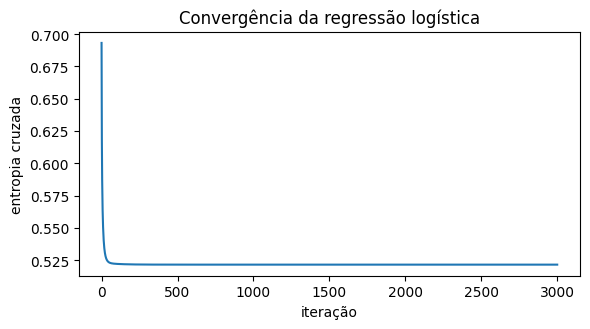

In [ ]:
def sigmoide(z): return 1 / (1 + np.exp(-np.clip(z, -35, 35)))

def gd_logistica(X, y, alpha=0.5, num_iter=3000, lam=0.0, hist=False):
    Xb = com_vies(X); N, d1 = Xb.shape; w = np.zeros(d1); H = []; pen = np.r_[0.0, np.ones(d1 - 1)]
    for _ in range(num_iter):
        p = sigmoide(Xb @ w)
        w = w - alpha * (Xb.T @ (p - y) / N + lam * pen * w / N)
        if hist: H.append(-(y * np.log(p + 1e-12) + (1 - y) * np.log(1 - p + 1e-12)).mean())
    return (w, H) if hist else w

w_lg, H_lg = gd_logistica(Xs, yc_all, hist=True)
print(pd.Series(w_lg, index=['intercepto'] + FEATS, name='GD (próprio)').round(3).to_string())
plt.figure(figsize=(6, 3.4)); plt.plot(H_lg); plt.xlabel('iteração'); plt.ylabel('entropia cruzada'); plt.title('Convergência da regressão logística'); plt.tight_layout(); plt.show()

In [ ]:
def cv_clf(fit_predict):
    acc = []
    for tr, te in folds:
        Xa, Xb_, _, _ = padroniza(X_all[tr], X_all[te]); acc.append((fit_predict(Xa, yc_all[tr], Xb_) == yc_all[te]).mean())
    return np.mean(acc), np.std(acc)

own_lg = lambda Xa, ya, Xb_: (sigmoide(com_vies(Xb_) @ gd_logistica(Xa, ya)) >= .5).astype(int)
# bônus: classificar pelo SINAL da regressão linear de DELTA (já que ALVO_MELHORA = [DELTA > 0])
accs = []
for tr, te in folds:
    Xa, Xb_, _, _ = padroniza(X_all[tr], X_all[te]); accs.append(((com_vies(Xb_) @ ridge_closed(Xa, y_all[tr], 0.0) > 0).astype(int) == yc_all[te]).mean())
A_SIGN = (np.mean(accs), np.std(accs))
base = np.mean([(yc_all[te] == (yc_all[tr].mean() >= .5)).mean() for tr, te in folds])

A_OWN = cv_clf(own_lg)
print(f'Logística (GD próprio) : acurácia 5-fold = {A_OWN[0]:.3f} ± {A_OWN[1]:.3f}')
print(f'Sinal da regressão lin.: acurácia 5-fold = {A_SIGN[0]:.3f} ± {A_SIGN[1]:.3f}')
print(f'Baseline majoritário   : {base:.3f}   |   Árvore de decisão (Etapa 1) ≈ 0,73–0,74')

Logística (GD próprio) : acurácia 5-fold = 0.741 ± 0.015
Sinal da regressão lin.: acurácia 5-fold = 0.735 ± 0.016
Baseline majoritário   : 0.631   |   Árvore de decisão (Etapa 1) ≈ 0,73–0,74


## 5. Comparação com o scikit-learn
**Esta é a única parte do notebook que usa o scikit-learn**, exigida pelo enunciado. Usamos as **mesmas partições** e a **mesma padronização** (ajustada no treino de cada partição) para os dois lados. Na logística, `C=1e10` equivale a "sem regularização", como no nosso gradiente.

In [ ]:
from sklearn.linear_model import LinearRegression, Ridge, LogisticRegression   # <- único import do scikit-learn deste notebook

# --- (a) univariada: coeficientes da fórmula fechada × LinearRegression
sk_uni = LinearRegression().fit(x.reshape(-1, 1), y_all)
print(f'Univariada | fórmula fechada: β0={b0:.4f}, β1={b1:.4f} | scikit-learn: β0={sk_uni.intercept_:.4f}, β1={sk_uni.coef_[0]:.4f}')

# --- (b) multivariada e Ridge: coeficientes no conjunto todo (padronizado)
sk_ols = LinearRegression().fit(Xs, y_all)
sk_rdg = Ridge(alpha=LAM).fit(Xs, y_all)
print('máx |GD − LinearRegression|          =', round(float(np.abs(w_gd - np.r_[sk_ols.intercept_, sk_ols.coef_]).max()), 6))
print('máx |Ridge fechada − Ridge sklearn|  =', round(float(np.abs(ridge_closed(Xs, y_all, LAM) - np.r_[sk_rdg.intercept_, sk_rdg.coef_]).max()), 6))

# --- (c) logística: coeficientes
sk_lg = LogisticRegression(C=1e10, max_iter=5000).fit(Xs, yc_all)
print('máx |GD logístico − LogisticRegression| =', round(float(np.abs(w_lg - np.r_[sk_lg.intercept_, sk_lg.coef_[0]]).max()), 5))

Univariada | fórmula fechada: β0=90.1346, β1=-0.3258 | scikit-learn: β0=90.1346, β1=-0.3258
máx |GD − LinearRegression|          = 0.0
máx |Ridge fechada − Ridge sklearn|  = 0.0
máx |GD logístico − LogisticRegression| = 0.00018


In [ ]:
# --- validação cruzada com as mesmas partições
def cv_sk_reg(make):
    r2s, rm = [], []
    for tr, te in folds:
        Xa, Xb_, _, _ = padroniza(X_all[tr], X_all[te]); p = make().fit(Xa, y_all[tr]).predict(Xb_)
        r2s.append(r2_score(y_all[te], p)); rm.append(rmse(y_all[te], p))
    return np.mean(r2s), np.std(r2s), np.mean(rm)

R_SK = cv_sk_reg(LinearRegression)
R_RIDGE_SK = cv_sk_reg(lambda: Ridge(alpha=LAM))
acc_sk = []
for tr, te in folds:
    Xa, Xb_, _, _ = padroniza(X_all[tr], X_all[te])
    acc_sk.append((LogisticRegression(C=1e10, max_iter=5000).fit(Xa, yc_all[tr]).predict(Xb_) == yc_all[te]).mean())
A_SK = (np.mean(acc_sk), np.std(acc_sk))
r2u, rmu = [], []
for tr, te in folds:
    m_ = LinearRegression().fit(x[tr].reshape(-1, 1), y_all[tr]); p = m_.predict(x[te].reshape(-1, 1))
    r2u.append(r2_score(y_all[te], p)); rmu.append(rmse(y_all[te], p))
R_UNI_SK = dict(r2=np.mean(r2u), rmse=np.mean(rmu))

resumo = pd.DataFrame({
    'Implementação própria': [R_UNI['r2'], R_UNI['rmse'], R_GD[0], R_GD[2], R_RIDGE[0], R_RIDGE[2], A_OWN[0]],
    'Scikit-learn':          [R_UNI_SK['r2'], R_UNI_SK['rmse'], R_SK[0], R_SK[2], R_RIDGE_SK[0], R_RIDGE_SK[2], A_SK[0]]},
    index=['R² univariada (fórmula fechada)', 'RMSE univariada', 'R² multivariada (GD)', 'RMSE multivariada',
           f'R² Ridge (λ={LAM:.0f})', 'RMSE Ridge', 'Acurácia logística (5-fold)'])
resumo.round(3)

,Implementação própria,Scikit-learn
R² univariada (fórmula fechada),0.254,0.254
RMSE univariada,11.102,11.102
R² multivariada (GD),0.287,0.287
RMSE multivariada,10.856,10.856
R² Ridge (λ=14),0.287,0.287
RMSE Ridge,10.855,10.855
Acurácia logística (5-fold),0.741,0.741


In [ ]:
lat = resumo.copy(); lat.index = [i.replace('²', '$^2$').replace('λ', r'$\lambda$') for i in lat.index]
print(lat.round(3).to_latex(float_format='%.3f', caption='Métricas da Etapa 2 (5-fold agrupado por município).', label='tab:etapa2'))

\begin{table}
\caption{Métricas da Etapa 2 (5-fold agrupado por município).}
\label{tab:etapa2}
\begin{tabular}{lrr}
\toprule
 & Implementação própria & Scikit-learn \\
\midrule
R$^2$ univariada (fórmula fechada) & 0.254 & 0.254 \\
RMSE univariada & 11.102 & 11.102 \\
R$^2$ multivariada (GD) & 0.287 & 0.287 \\
RMSE multivariada & 10.856 & 10.856 \\
R$^2$ Ridge ($\lambda$=14) & 0.287 & 0.287 \\
RMSE Ridge & 10.855 & 10.855 \\
Acurácia logística (5-fold) & 0.741 & 0.741 \\
\bottomrule
\end{tabular}
\end{table}



## 6. Discussão
- **Univariada:** $\hat\beta_1\approx-0{,}33$: cada ponto a mais em 2021 reduz em ~0,33 ponto a variação esperada. $R^2\approx0{,}25$ no 5-fold. Como discutido na seção 1, esse efeito é em grande parte **regressão à média**.
- **Multivariada:** $R^2\approx0{,}29$ (RMSE ≈ 10,9 pontos, contra desvio-padrão de 12,9 do alvo). O atributo dominante é `MEDIA_12_MT_2021` (−6,9 pontos por desvio-padrão); região, ruralidade, dependência e IDHM-Renda têm coeficientes pequenos (|β| ≲ 2,5). O gradiente descendente próprio coincide com as equações normais e com o `LinearRegression` até a 6ª casa decimal.
- **Ridge:** com ~3,5 mil exemplos e só 8 atributos, a regularização **quase não ajuda**: o melhor λ (~14) dá o mesmo $R^2$ do MQO, e λ grande só encolhe os coeficientes (curva de coeficientes) e piora o ajuste. A curva é útil aqui para ver **quais coeficientes encolhem primeiro** (os das regiões e de `Rural`, pequenos).
- **Logística:** acurácia ≈ 74% no 5-fold, equivalente à árvore da Etapa 1 (≈ 73–74%) e ~11 pontos acima do baseline (63,1%). Classificar pelo sinal da regressão linear de $\Delta$ dá resultado quase igual (≈ 73,5%), o que é coerente: `ALVO_MELHORA` é o sinal de $\Delta$.
- **Limitações:** associação, não causalidade; SAEB 2021 aplicado na pandemia; IDHM de 2010; relação possivelmente não linear (a árvore da Etapa 1 capta interações com `CO_UF` que o modelo linear não vê).